# Fig 7A: Plot cell counts with Cdk4/6i

In [18]:
import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
from mpl_toolkits.axes_grid1 import Divider, Size
import pandas as pd
import seaborn as sns
import math
from pathlib import Path
import re
import sys
import json

from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

In [2]:
SAVEFILES = True
OVERWRITE = True
SET_JPARAM = False

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)

    
DATADIR = Path("../../Data/cell_populations")

rcParams.update({'figure.autolayout': True})

# add path to fit functions
sys.path.insert(0, "./../../Python")
from fits import emg_fit_func

In [3]:
f = open(SAVEDIR / 'cell_counts_di_55kpa_erl.json')
# f = open('C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl.json')
cell_counts_di_55erl = json.load(f)

In [4]:
# Load DMSO +Cdk4/6i 55kPa
cell_counts_cdk46i_55_df = pd.read_csv(SAVEDIR / 'cdk46i_dmso_cell_counts.csv', delimiter=',')



In [5]:
# include samples
if SET_JPARAM:
    filepaths = os.listdir(SAVEDIR)
    filenames = [f for f in filepaths if re.search('^cellcount_.*jparam_2.csv$', f)]
    filepaths = [Path(SAVEDIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)
else:
    filepaths = os.listdir(DATADIR)
    filenames = [f for f in filepaths if re.search('^cell_counts.*orig.csv$', f)]
    filepaths = [Path(DATADIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)

[WindowsPath('../../Data/cell_populations/cell_counts_0.6 kPa DMSO_0_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_0.6 kPa DMSO_1_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_0.6 kPa DMSO_2_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_0.6 kPa erlotinib_0_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_0.6 kPa erlotinib_1_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_0.6 kPa erlotinib_2_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_4 kPa DMSO_0_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_4 kPa DMSO_1_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_4 kPa DMSO_2_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_4 kPa erlotinib_0_param_orig.csv'), WindowsPath('../../Data/cell_populations/cell_counts_4 kPa erlotinib_1_param_orig.csv'), WindowsPath('../../Data/cell_populatio

In [6]:
def calc_doub(filename):
    tmp = np.loadtxt(filename, delimiter=',')
    
    t = np.arange(0,121)
    new_r = []
    for num in t:
        vals = tmp[tmp[:,0]<=num]
        new_r.append([num, vals[-1,1]])
    
    doubs = []
    for num in t:
        doub = math.log(new_r[num][1]/new_r[0][1])/math.log(2)
        doubs.append([num, doub])
        
    return doubs
    

In [7]:
all_doubs = pd.DataFrame(columns=['Condition','Time','Doub'])
for filename in filepaths:
    doub = calc_doub(filename)
    tmp = [x[1] for x in doub]
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    t = np.arange(0,121)
    data = {
        'Condition': [name]*len(t), 
        'Time': t,
        'Doub': tmp}
    tmp_df = pd.DataFrame(data)
    
    all_doubs = pd.concat([all_doubs, tmp_df], ignore_index=True)
    


In [8]:
doub_arr = np.zeros((121,18))
n = 0
for filename in filepaths:
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    tmp = all_doubs.loc[all_doubs['Condition'] == name]
    doub_arr[:,n]=tmp['Doub']
    n+=1

    

In [10]:
means=[np.mean(doub_arr[:,0:2],axis=1), np.mean(doub_arr[:,3:5],axis=1), np.mean(doub_arr[:,6:8],axis=1), 
       np.mean(doub_arr[:,9:11],axis=1), np.mean(doub_arr[:,12:14],axis=1), np.mean(doub_arr[:,15:17],axis=1)]
    
stdevs=[np.std(doub_arr[:,0:2],axis=1), np.std(doub_arr[:,3:5],axis=1), np.std(doub_arr[:,6:8],axis=1), 
       np.std(doub_arr[:,9:11],axis=1), np.std(doub_arr[:,12:14],axis=1), np.std(doub_arr[:,15:17],axis=1)]


In [11]:
run_time = 120
all_doubs = np.zeros((360,3))
for ii in range(3):
    cell_count = cell_counts_di_55erl['0.4'][ii]
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    all_doubs[:,ii] = pop_dubs

In [12]:
mean_treat = np.mean(all_doubs, axis=1)
std_treat = np.std(all_doubs, axis=1)
t_sim = np.arange(0, run_time, 1 / 3)

In [13]:
run_time = 120
all_doubs = np.zeros((360,3))
for ii in range(3):
    tmp_df = cell_counts_cdk46i_55_df[cell_counts_cdk46i_55_df['run']==ii]
    cell_count = [[x, y] for x,y in zip(tmp_df['0'], tmp_df['1'])]
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    all_doubs[:,ii] = pop_dubs

In [14]:
mean_cdki = np.mean(all_doubs, axis=1)
std_cdki = np.std(all_doubs, axis=1)


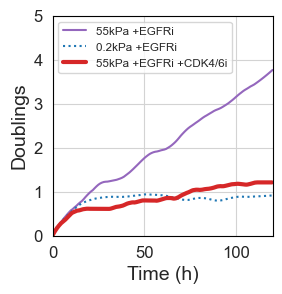

In [21]:
win = 21
pol = 2
size = (3,3)
c1 = "tab:blue"
c2 = "tab:red"
c3 = "tab:purple"
xmin = 0
xmax = 120
ymin = 0
ymax = 5

params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

BOX = 2.2
LEFT, BOTTOM, RIGHT, TOP = 0.70, 0.55, 0.12, 0.12   # margins in inches

figW = LEFT + BOX + RIGHT
figH = BOTTOM + BOX + TOP
fig = plt.figure(figsize=(figW, figH))
fig.set_layout_engine('none')

h = [Size.Fixed(LEFT),   Size.Fixed(BOX)]
v = [Size.Fixed(BOTTOM), Size.Fixed(BOX)]
div = Divider(fig, (0, 0, 1, 1), h, v, aspect=False)
axes = fig.add_axes(div.get_position(), axes_locator=div.new_locator(nx=1, ny=1))

axes.plot(t, savgol_filter(means[5],win,pol), ls='-', color=c3, label='55kPa +EGFRi')
axes.plot(t, savgol_filter(means[1],win,pol), ls=':', color=c1, label='0.2kPa +EGFRi')
# axes.plot(t_sim, savgol_filter(mean_cdki,win,pol), ls='-.', color='black', label='55kPa +CDK4/6i')
axes.plot(t_sim, savgol_filter(mean_treat,win,pol), lw=3, color=c2, label='55kPa +EGFRi +CDK4/6i')


axes.set_xlim([xmin, xmax])
axes.set_ylim([ymin, ymax])
axes.grid(color='lightgray')
axes.set_xlabel('Time (h)')
axes.set_ylabel('Doublings')

axes.legend(fontsize=8.4, loc="upper left")

filepath = Path(SAVEDIR,'fig7a_cellcounts.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)